In [3]:
import pandas as pd
import numpy as np

In [6]:
clim = pd.read_csv('Train_1.csv') # loading the dataset
clim

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3141,ID_2CDAAE58,Rural,Female,2022-05-06,92.0,21.869711,24.824496,19.501874,4.250624,0.572884,33.506221,"Kiboyo, Iganga, Uganda",0
3142,ID_8099FB9C,Peri_urban,Male,2022-05-07,0.0,21.957913,25.210808,19.286763,4.133601,0.614154,33.483544,"Nakavule B, Iganga, Uganda",1
3143,ID_8A614F8B,Rural,Female,2022-05-15,0.0,22.436613,26.813967,18.726832,1.473170,0.550000,33.450000,"Luyira, Mayuge, Uganda",0
3144,ID_CB4F8F61,Peri_urban,Male,2022-05-18,0.0,22.445975,25.554302,19.487528,1.220220,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1


# DATA inspection 

In [9]:

clim.info()  #gives us information of the dataset, columns and their datatype

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
dtypes: float64(7), int64(1), object(5)
memory usage: 319.6+ KB


In [12]:
clim.describe() # gives statistical summary of all the numerical column

,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,is_climate_sensitive
count,3146.000000,3146.000000,3146.000000,3146.000000,3146.000000,3146.000000,3146.000000,3146.000000
mean,24.243484,22.066541,26.206879,18.514193,1.519907,0.630242,33.407442,0.650668
std,31.428833,1.095122,1.691347,0.891524,1.621088,0.172728,0.579933,0.476835
min,0.000000,18.852803,20.884623,15.018778,0.000000,0.089819,30.782817,0.000000
25%,0.000000,21.319885,25.260527,17.954814,0.286814,0.564758,33.473515,0.000000
50%,3.000000,21.931299,26.081829,18.510478,1.034344,0.591961,33.483544,1.000000
75%,49.000000,22.652860,27.015877,19.040655,2.222345,0.608396,33.519695,1.000000
max,110.000000,27.012223,34.080947,21.849602,16.606523,1.187892,34.226647,1.000000


In [15]:
clim.shape # there are 3146 records with 13 columns/features

(3146, 13)

In [18]:
clim.columns # there are 13 features in this dataset

Index(['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature',
       'max_temperature', 'min_temperature', 'precipitation', 'latitude',
       'longitude', 'location', 'is_climate_sensitive'],
      dtype='object')

In [21]:
clim.isnull().mean().sum() # finding missing values
# ther are 0 missing value across the dataset.

0.0

In [45]:
clim.duplicated().sum() # identifying  duplicated values across the dataset
# we have no duplicated values.

0

In [24]:
# checking the data 
clim.dtypes  # deathdate is an object, so we will need to convert it to date type.

ID                       object
zone                     object
gender                   object
deathdate                object
age                     float64
avg_temperature         float64
max_temperature         float64
min_temperature         float64
precipitation           float64
latitude                float64
longitude               float64
location                 object
is_climate_sensitive      int64
dtype: object

In [27]:
# changing the death date from object to a date time
clim['deathdate']=pd.to_datetime(clim['deathdate'])

In [30]:
clim['deathdate'].dtype
# deathdate has successfully been converted to date datatype

dtype('<M8[ns]')

In [35]:
# identifying the unique categories and their frequencyin only categorical datatype
# this helps us to understand what exist in each categories  and how they are represented. 
categorical_columns = clim.select_dtypes(
    include='object'
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(clim[col].value_counts())


ID
ID
ID_1FE951BD    1
ID_1AD133C0    1
ID_ECA2EA30    1
ID_D14B7E30    1
ID_A14D5C7A    1
              ..
ID_CCD4679E    1
ID_485AA2DD    1
ID_54914F4C    1
ID_D3F6BB00    1
ID_64F97593    1
Name: count, Length: 3146, dtype: int64

zone
zone
Rural         1972
Peri_urban    1174
Name: count, dtype: int64

gender
gender
Male      1645
Female    1501
Name: count, dtype: int64

location
location
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda       211
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda                       207
Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda                                                          158
Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda    155
Nawanzu, Iganga, Uganda                                                                                      

In [38]:
categorical_cols = clim.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(clim[col].nunique())  # unique categories in each categorical column


ID:
3146

zone:
2

gender:
2

location:
39


In [48]:
# summary of the catogorical data
# zone recorded rural observation makes up 62,7% while peri-urban recorded 37.3%
# the gender is faily distributed with slightly more males than females
# location has 39 distinct value.

In [50]:
# extracting datetime to have month, day and year. 
# so we can investigate whether climate sensitivity varies by year or month
clim['year'] = clim['deathdate'].dt.year
clim['month'] = clim['deathdate'].dt.month
clim['day'] = clim['deathdate'].dt.day

In [52]:
clim

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,year,month,day
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,2007,10,2
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,1,5
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,2008,2,14
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,2,15
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,2008,2,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3141,ID_2CDAAE58,Rural,Female,2022-05-06,92.0,21.869711,24.824496,19.501874,4.250624,0.572884,33.506221,"Kiboyo, Iganga, Uganda",0,2022,5,6
3142,ID_8099FB9C,Peri_urban,Male,2022-05-07,0.0,21.957913,25.210808,19.286763,4.133601,0.614154,33.483544,"Nakavule B, Iganga, Uganda",1,2022,5,7
3143,ID_8A614F8B,Rural,Female,2022-05-15,0.0,22.436613,26.813967,18.726832,1.473170,0.550000,33.450000,"Luyira, Mayuge, Uganda",0,2022,5,15
3144,ID_CB4F8F61,Peri_urban,Male,2022-05-18,0.0,22.445975,25.554302,19.487528,1.220220,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1,2022,5,18


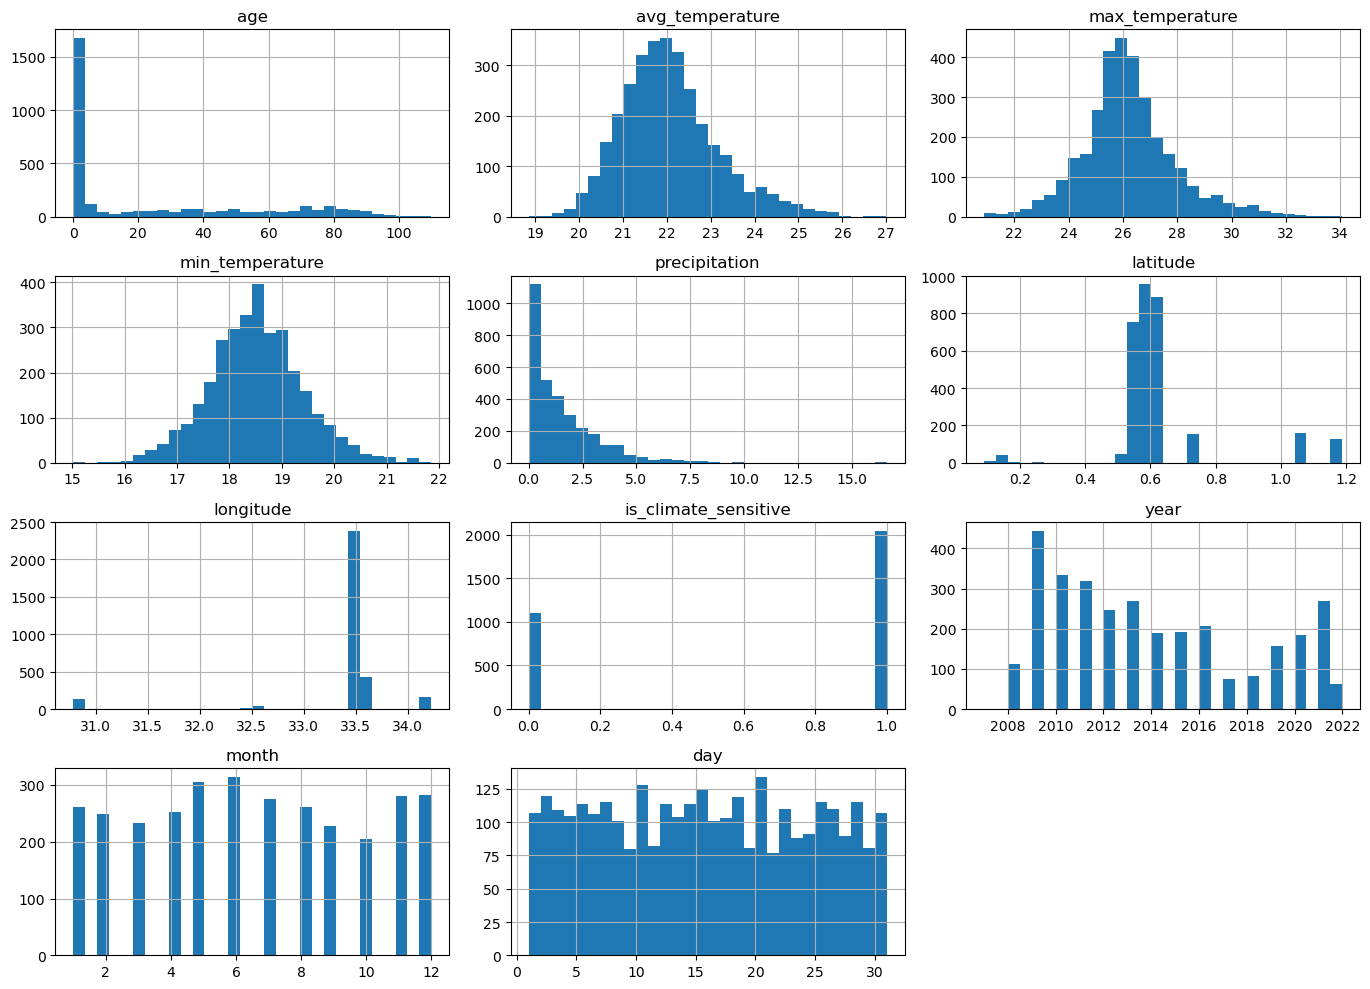

In [59]:
# inspecting the numerical distributions
import matplotlib.pyplot as plt
import seaborn as sns
numeric_cols = clim.select_dtypes(include='number').columns

clim[numeric_cols].hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

In [62]:
clim[numeric_cols].skew().sort_values(ascending=False)
# checking for skweness
# checking if the values in the data are evenly distributed around the centre or if they strech more towars one side.

precipitation           1.981325
latitude                1.769559
age                     0.936120
avg_temperature         0.690679
max_temperature         0.535965
year                    0.465189
min_temperature         0.150815
day                     0.040899
month                   0.032724
is_climate_sensitive   -0.632350
longitude              -3.689858
dtype: float64

In [ ]:
#Summary of Skewness Analysis

# The skewness analysis revealed that most numerical variables have varying degrees of asymmetry.
# Precipitation (1.98), latitude (1.77) and age (0.94) are positively skewed, 
# indicating that their distributions have longer tails towards higher values. 
# Some location may have little rainfall while other location may have heavy rainfall.
# (in the dataset, rainfall levels are generally low across the observation with only few observations redording higher rainfall)
# (geographical o servations are not evenly distributed across geographical latitude range in the dataset)
# (The dataset contains more younger individuals than older individuals with few observations among older age group)

# Average temperature (0.69) and maximum temperature (0.54) also show slight positive skewness.
# Minimum temperature (0.15), day (0.04), month (0.03) and year (0.47) are relatively
# symmetrical. 

#Longitude (-3.69) displays strong negative skewness,suggesting a longer tail towards lower values. 
# (the dataset distribution may be concentrated towards the eastern longitude cordinates with fewer observations at the western end)
# The target variable, is_climate_sensitive (-0.63), is also negatively skewed, 
# reflecting the unequal distribution of its two classes.(the dataset concentrated more towards climate_sensitive deaths than non climate sensitive death

# Overall finding: Precipitation, latitude, age and longitude require further investigation
# because of their noticeable skewness. 
# These patterns will guide our subsequent outlier analysis and preprocessing decisions. 
# Skewness alone, however, does not mean that these variables need transformation or removal.

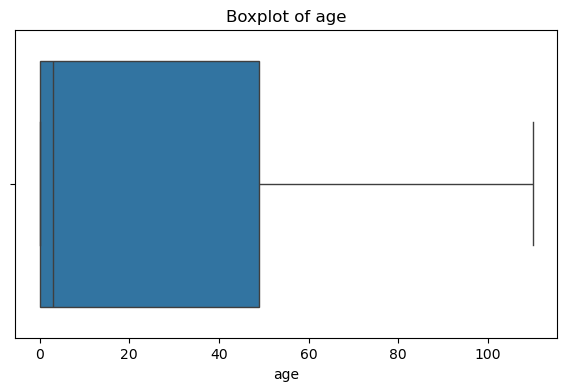

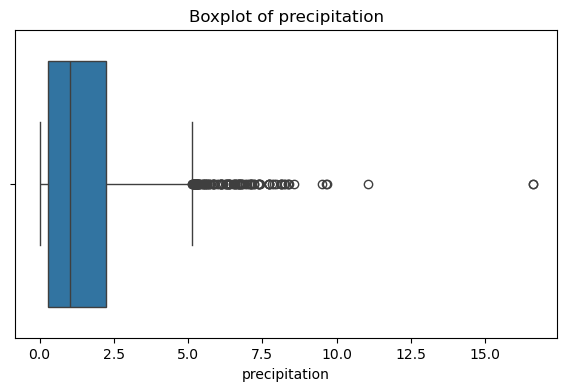

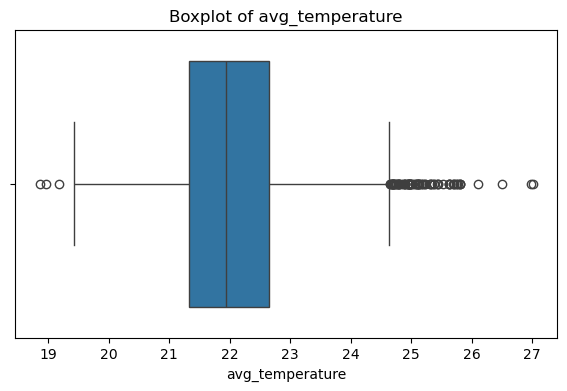

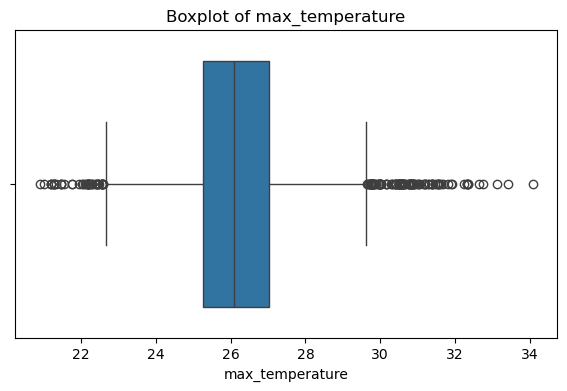

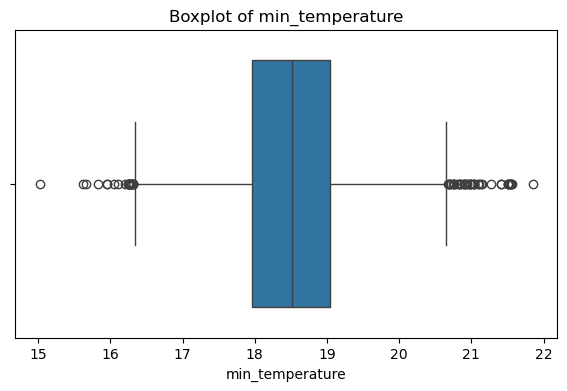

In [66]:
# identifying outliers in the given column
features = ['age', 'precipitation', 'avg_temperature',
            'max_temperature', 'min_temperature']

for col in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=clim[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [69]:
# boxplot interpretation
# Precipitation :Several points appear above the upper whisker. These are potential high-value outliers and may explain the strong positive skewness.
# average temperature:There are potential outliers on both sides of the distribution.
# max temp:Several potential outliers appear above and below the whiskers.
# min temp: There are also a few potential outlying observations.

In [95]:
# let's run some correlation analysis for some numerical columns
corr_matrix = clim.corr(numeric_only=True)

corr_matrix.round(3)

,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,is_climate_sensitive,year,month,day
age,1.000,0.019,0.028,0.003,-0.039,0.016,-0.025,-0.443,-0.140,0.015,-0.017
avg_temperature,0.019,1.000,0.916,0.555,-0.459,0.013,-0.028,-0.030,0.110,-0.368,-0.033
max_temperature,0.028,0.916,1.000,0.275,-0.540,0.015,-0.022,-0.036,0.078,-0.294,-0.031
min_temperature,0.003,0.555,0.275,1.000,0.110,-0.004,-0.016,-0.014,0.114,-0.305,-0.028
precipitation,-0.039,-0.459,-0.540,0.110,1.000,0.002,-0.015,0.028,-0.013,0.023,0.037
latitude,0.016,0.013,0.015,-0.004,0.002,1.000,-0.374,-0.013,0.003,-0.020,0.025
longitude,-0.025,-0.028,-0.022,-0.016,-0.015,-0.374,1.000,-0.005,-0.006,0.011,-0.029
is_climate_sensitive,-0.443,-0.030,-0.036,-0.014,0.028,-0.013,-0.005,1.000,-0.174,-0.014,-0.011
year,-0.140,0.110,0.078,0.114,-0.013,0.003,-0.006,-0.174,1.000,-0.044,0.002
month,0.015,-0.368,-0.294,-0.305,0.023,-0.020,0.011,-0.014,-0.044,1.000,0.012


In [ ]:
# the correlation analysis reveals that:
# Average temperature and maximum temperature have a very strong positive correlation 
# (0.916), suggesting potential multicollinearity.(they contain overlapping information)
#( this might suggest that when av temp increases, max temp also tends to increase and vice versa)
# Age has a moderate negative correlation with climate sensitivity (-0.443).
# Temperature variables have moderate negative relationships with precipitation.
# Most other features have weak linear relationships.
# Age appears to be an important variable to investigate further when predicting climate sensitivity.

In [76]:
# to investigate multicollineraity among some features / identify overlapping information
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

In [79]:
numerical_features = clim.select_dtypes(include=['int64', 'float64']).drop(
    columns=['is_climate_sensitive', 'ID'],
    errors='ignore'
)# removed the target feature that would be a predictor

In [81]:
vif_data = pd.DataFrame()

vif_data['Feature'] = numerical_features.columns

vif_data['VIF'] = [
    variance_inflation_factor(numerical_features.values, i)
    for i in range(numerical_features.shape[1])
]

vif_data = vif_data.sort_values(by='VIF', ascending=False)

vif_data

,Feature,VIF
1,avg_temperature,7129.659538
2,max_temperature,2979.302166
3,min_temperature,1447.889828
6,longitude,486.112330
5,latitude,14.053293
4,precipitation,3.105564
0,age,1.598651


In [ ]:
#The analysis suggests that several geographical and temperature-related variables contain 
# overlapping information. 
# This could affect the stability and interpretation of coefficients in regression-based models, particularly Logistic Regression.

In [83]:
# before deciding to remove any features, running a corelation between the selected features
# to help us understand better.
clim[['avg_temperature',
    'max_temperature',
    'min_temperature']].corr()

,avg_temperature,max_temperature,min_temperature
avg_temperature,1.000000,0.916292,0.555363
max_temperature,0.916292,1.000000,0.274598
min_temperature,0.555363,0.274598,1.000000


In [85]:
clim[['longitude', 'latitude']].corr()

,longitude,latitude
longitude,1.000000,-0.373849
latitude,-0.373849,1.000000


In [ ]:
# findings
# average and minimum temperature have moderate relationship
# average and maximum temperature have strong 
# max and min temperature have weak relationship
# longitude and latitude have weak to moderate negative relationship 

In [87]:
corr_matrix = numerical_features.corr()

corr_matrix.round(3)

,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude
age,1.000,0.019,0.028,0.003,-0.039,0.016,-0.025
avg_temperature,0.019,1.000,0.916,0.555,-0.459,0.013,-0.028
max_temperature,0.028,0.916,1.000,0.275,-0.540,0.015,-0.022
min_temperature,0.003,0.555,0.275,1.000,0.110,-0.004,-0.016
precipitation,-0.039,-0.459,-0.540,0.110,1.000,0.002,-0.015
latitude,0.016,0.013,0.015,-0.004,0.002,1.000,-0.374
longitude,-0.025,-0.028,-0.022,-0.016,-0.015,-0.374,1.000


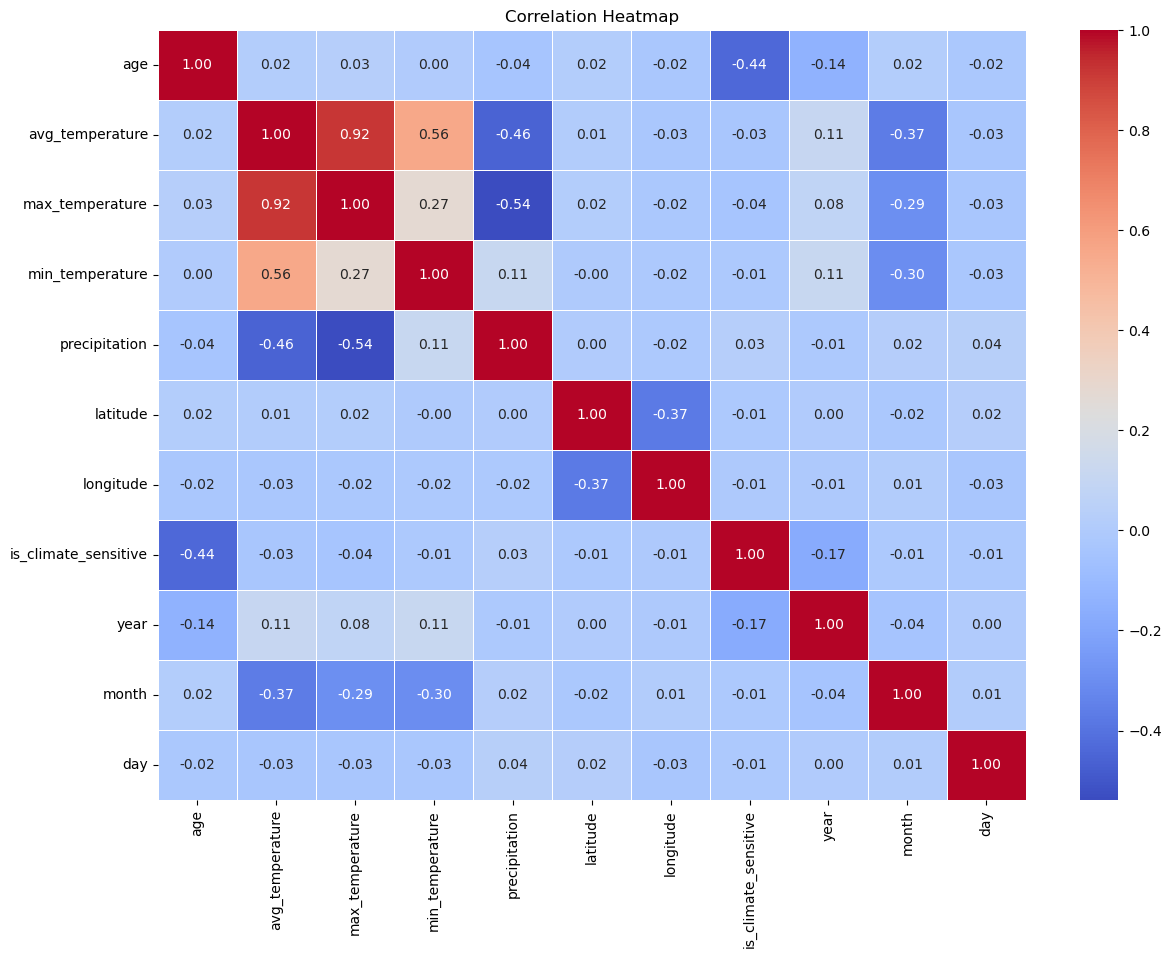

In [98]:
# visual using hetmaps to show their correlation
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [91]:
# checking for how much each independent variable is explained by the other independent variable with a constant
# 
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(numerical_features)

vif_results = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

vif_results

,Feature,VIF
0,const,4748.492374
1,age,1.002992
2,avg_temperature,17.617454
3,max_temperature,12.353989
4,min_temperature,3.363170
5,precipitation,1.678936
6,latitude,1.162845
7,longitude,1.165094


In [ ]:
# The VIF analysis revealed substantial multicollinearity among average temperature (17.62)
# and maximum temperature (12.35), suggesting considerable overlap in the information provided by these variables. 
# Minimum temperature recorded a VIF of 3.36, while age, precipitation, latitude and longitude had VIF values below 2, 
# indicating relatively low multicollinearity.
# Based on these findings, further investigation of the temperature variables is recommended to determine whether feature selection is necessary,
# particularly for the Logistic Regression model.

In [101]:
# identifying the distribution of the target feature
clim['is_climate_sensitive'].value_counts() 
# climate that is sensitive is assigned 1 while not sensitive is assigned 0

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64

In [104]:
clim['is_climate_sensitive'].value_counts(normalize = True)* 100
# approximately 65 out of 100 distributionare classified as climate sensitive 
# while the 35 are classified as not sensitive
# this show the dataset is moderately imbalanced though, not severely.
# a classifer may favour the majority class when making decisons hence, we will look at
# considering various option to get the best such as logistic regression, decision tree, random forest

is_climate_sensitive
1    65.066751
0    34.933249
Name: proportion, dtype: float64

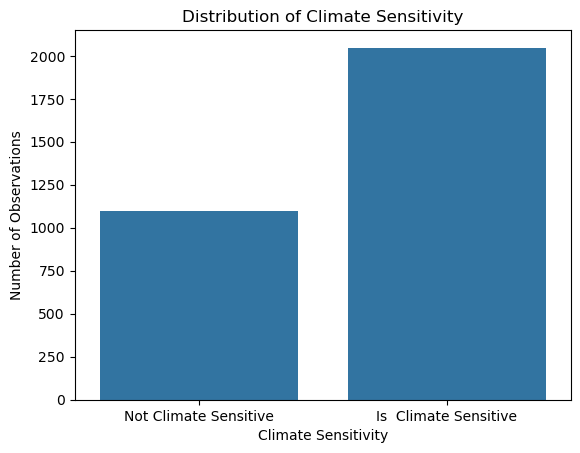

In [107]:
# visualizing this climate distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=clim, x='is_climate_sensitive')

plt.title('Distribution of Climate Sensitivity')
plt.xlabel('Climate Sensitivity')
plt.ylabel('Number of Observations')
plt.xticks([0, 1], ['Not Climate Sensitive', 'Is  Climate Sensitive'])
plt.show()